# Telco Customer Churn – Prediction & Deployment
End-to-end classification mini-project: preprocessing → 7-model comparison → tuning → saving → Streamlit app.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, joblib, json
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, classification_report)
RANDOM_STATE = 42

## Step 1: Data Preprocessing

In [2]:
df = pd.read_csv('Telco-Customer-Churn.csv')
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 1.1 Missing values and hidden spaces
`TotalCharges` is read as text because some rows contain a blank space (`' '`) instead of a number. These are new customers with `tenure = 0`.

In [3]:
print('Missing values (before):', df.isna().sum().sum())
print('Blank-string TotalCharges rows:', (df['TotalCharges'].str.strip() == '').sum())

# strip hidden spaces in every text column, then convert TotalCharges to numeric
for c in df.select_dtypes('object').columns:
    df[c] = df[c].str.strip()
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].replace('', np.nan))
print('NaN in TotalCharges after conversion:', df['TotalCharges'].isna().sum())
print(df.loc[df['TotalCharges'].isna(), ['tenure','MonthlyCharges','TotalCharges']].head())

# These customers have tenure = 0 (never billed yet) -> TotalCharges = 0 is the logical value
df['TotalCharges'] = df['TotalCharges'].fillna(0)
df = df.drop(columns='customerID')   # identifier, not a feature
print('Missing values (after):', df.isna().sum().sum())

Missing values (before): 0
Blank-string TotalCharges rows: 11
NaN in TotalCharges after conversion: 11
      tenure  MonthlyCharges  TotalCharges
488        0           52.55           NaN
753        0           20.25           NaN
936        0           80.85           NaN
1082       0           25.75           NaN
1340       0           56.05           NaN
Missing values (after): 0


### 1.2 Target distribution (is it imbalanced?)

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


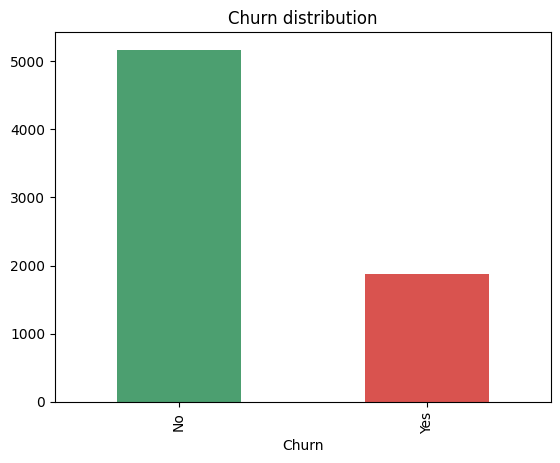

In [4]:
print(df['Churn'].value_counts())
print(df['Churn'].value_counts(normalize=True).round(3))
df['Churn'].value_counts().plot(kind='bar', color=['#4c9f70','#d9534f'], title='Churn distribution'); plt.show()

The data is **imbalanced**: about 73.5% stay and 26.5% churn. A model that predicts "No churn" for everyone would already get ~73.5% accuracy while catching zero churners.

### 1.3 Encoding, train/test split, and scaling
- Target: `Churn` → `Yes=1`, `No=0`.
- Categorical columns → **One-Hot Encoding** (nominal categories, no natural order).
- Numeric columns (`tenure`, `MonthlyCharges`, `TotalCharges`) → **StandardScaler**.
- Split first (stratified 80/20), and fit the encoder/scaler **on the training set only** inside a `ColumnTransformer`, to avoid data leakage. Putting it inside a `Pipeline` also means the saved model accepts raw customer data directly (needed by the Streamlit app).

In [5]:
X = df.drop(columns='Churn')
y = (df['Churn'] == 'Yes').astype(int)

num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = [c for c in X.columns if c not in num_cols]   # includes SeniorCitizen (0/1) treated as category
print('Numeric:', num_cols); print('Categorical:', cat_cols)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape, y_train.mean().round(3), y_test.mean().round(3))

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), cat_cols),
])

Numeric: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
(5634, 19) (1409, 19) 0.265 0.265


## Step 2: Baseline Training & Model Comparison

### Metric choice and why Accuracy alone is misleading
Churn is imbalanced (~26% churners), so **Accuracy can look good while the model misses most churners**. For the business, the important class is *Churn = Yes*:
- **Recall (churn class)**: of the customers who really leave, how many do we catch? A missed churner is a lost customer.
- **Precision (churn class)**: of the customers we flag, how many really leave? Low precision wastes retention budget (discounts, calls).
- **F1-score (churn class)**: the balance between the two → **our main metric for choosing the best model**.
- **ROC-AUC** and the **Confusion Matrix** are used as supporting views.

All metrics are computed for the positive class (Churn = Yes) on the untouched test set.

In [6]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'SVM':                 SVC(probability=True, random_state=RANDOM_STATE),
    'KNN':                 KNeighborsClassifier(),
    'Decision Tree':       DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Random Forest':       RandomForestClassifier(random_state=RANDOM_STATE),
    'AdaBoost':            AdaBoostClassifier(random_state=RANDOM_STATE),
    'XGBoost':             XGBClassifier(eval_metric='logloss', random_state=RANDOM_STATE),
}

rows, fitted = [], {}
for name, clf in models.items():
    pipe = Pipeline([('prep', preprocessor), ('clf', clf)]).fit(X_train, y_train)
    pred = pipe.predict(X_test); proba = pipe.predict_proba(X_test)[:, 1]
    fitted[name] = pipe
    rows.append({'Model': name,
                 'Accuracy':  accuracy_score(y_test, pred),
                 'Precision': precision_score(y_test, pred),
                 'Recall':    recall_score(y_test, pred),
                 'F1':        f1_score(y_test, pred),
                 'ROC-AUC':   roc_auc_score(y_test, proba)})
results = pd.DataFrame(rows).set_index('Model').sort_values('F1', ascending=False).round(4)
results

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8420
AdaBoost,0.8006,0.6440,0.5561,0.5968,0.8432
SVM,0.7963,0.6516,0.5000,0.5658,0.7941
XGBoost,0.7764,0.5897,0.5187,0.5519,0.8205
KNN,0.7622,0.5543,0.5321,0.5430,0.7768
Random Forest,0.7814,0.6122,0.4813,0.5389,0.8208
Decision Tree,0.7253,0.4831,0.4973,0.4901,0.6523


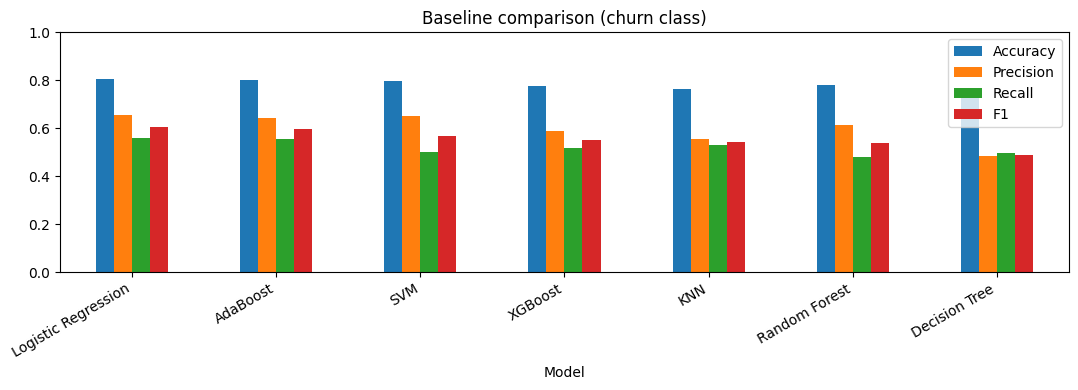

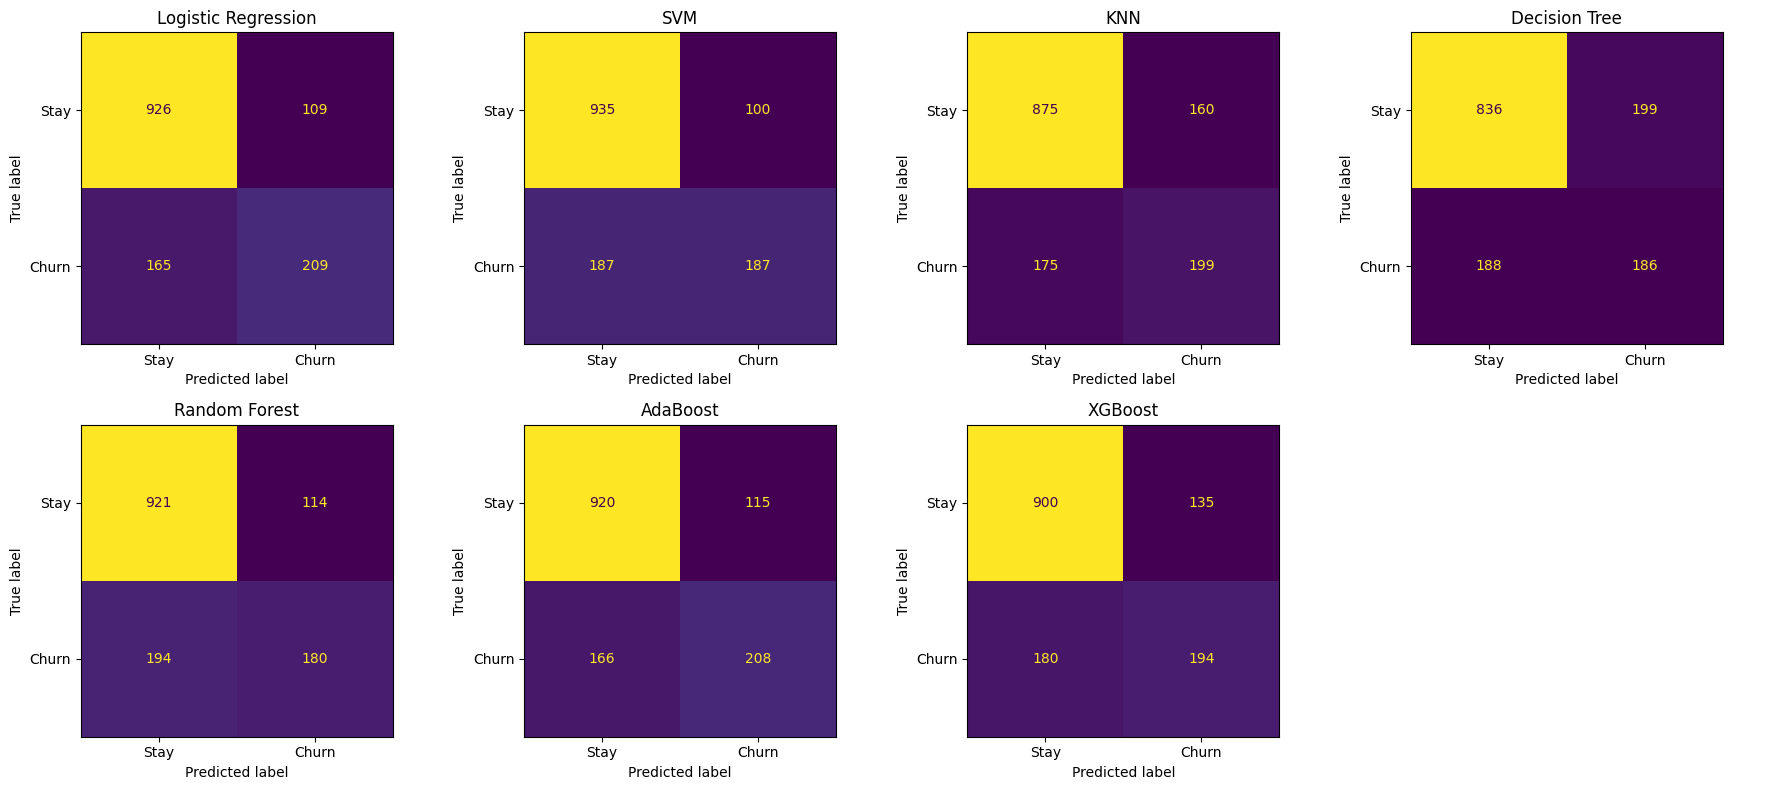

In [7]:
results[['Accuracy','Precision','Recall','F1']].plot(kind='bar', figsize=(11,4), title='Baseline comparison (churn class)')
plt.ylim(0,1); plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.savefig('model_comparison.png', dpi=130); plt.show()

fig, axes = plt.subplots(2, 4, figsize=(18, 8)); axes = axes.ravel()
for ax, (name, pipe) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test, display_labels=['Stay','Churn'], ax=ax, colorbar=False)
    ax.set_title(name)
axes[-1].axis('off'); plt.tight_layout(); plt.savefig('confusion_matrices.png', dpi=110); plt.show()

In [8]:
best_name = results['F1'].idxmax()
print('Best baseline model by F1:', best_name)
print(results.loc[best_name])
print(classification_report(y_test, fitted[best_name].predict(X_test), target_names=['Stay','Churn']))

Best baseline model by F1: Logistic Regression
Accuracy     0.8055
Precision    0.6572
Recall       0.5588
F1           0.6040
ROC-AUC      0.8420
Name: Logistic Regression, dtype: float64
              precision    recall  f1-score   support

        Stay       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



**Reading the results:** Accuracy values are close to each other (~73–80%), but Recall on the churn class differs a lot between models. This is exactly why Accuracy alone would be misleading here.

## Step 3: Model Fine-Tuning
We tune the best baseline model with `GridSearchCV` (5-fold stratified CV on the training set only). The scoring is **F1 of the churn class**, which is consistent with our metric choice (optimising plain accuracy would push the model toward ignoring churners). Accuracy is still reported for comparison.

In [9]:
param_grids = {
    'Logistic Regression': {'clf__C': [0.01, 0.1, 1, 10], 'clf__class_weight': [None, 'balanced']},
    'SVM': {'clf__C': [0.1, 1, 10], 'clf__kernel': ['rbf', 'linear'], 'clf__class_weight': [None, 'balanced']},
    'KNN': {'clf__n_neighbors': [5, 9, 15, 25], 'clf__weights': ['uniform', 'distance']},
    'Decision Tree': {'clf__max_depth': [3, 5, 8, None], 'clf__min_samples_leaf': [1, 10, 30], 'clf__class_weight': [None, 'balanced']},
    'Random Forest': {'clf__n_estimators': [200, 400], 'clf__max_depth': [6, 10, None],
                      'clf__min_samples_leaf': [1, 5], 'clf__class_weight': [None, 'balanced']},
    'AdaBoost': {'clf__n_estimators': [100, 200, 400], 'clf__learning_rate': [0.05, 0.1, 0.5, 1.0]},
    'XGBoost': {'clf__n_estimators': [100, 300], 'clf__max_depth': [3, 5], 'clf__learning_rate': [0.03, 0.1],
                'clf__scale_pos_weight': [1, 2.77]},   # 2.77 = n_stay / n_churn
}
pipe = Pipeline([('prep', preprocessor), ('clf', models[best_name])])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(pipe, param_grids[best_name], scoring='f1', cv=cv, n_jobs=-1, verbose=1)
grid.fit(X_train, y_train)
print('Best params:', grid.best_params_)
print('Best CV F1 :', round(grid.best_score_, 4))

Fitting 5 folds for each of 8 candidates, totalling 40 fits


Best params: {'clf__C': 1, 'clf__class_weight': 'balanced'}
Best CV F1 : 0.6293


           Baseline   Tuned
Accuracy     0.8055  0.7381
Precision    0.6572  0.5043
Recall       0.5588  0.7834
F1           0.6040  0.6136
ROC-AUC      0.8420  0.8415
              precision    recall  f1-score   support

        Stay       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



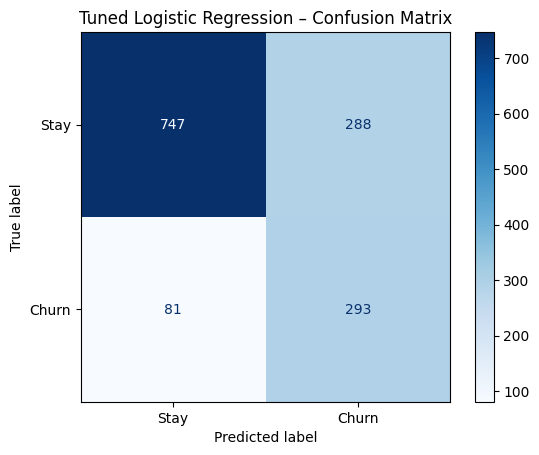

In [10]:
final_model = grid.best_estimator_
pred  = final_model.predict(X_test); proba = final_model.predict_proba(X_test)[:, 1]
comparison = pd.DataFrame({
    'Baseline': results.loc[best_name, ['Accuracy','Precision','Recall','F1','ROC-AUC']],
    'Tuned': [accuracy_score(y_test, pred), precision_score(y_test, pred), recall_score(y_test, pred),
              f1_score(y_test, pred), roc_auc_score(y_test, proba)]}, index=['Accuracy','Precision','Recall','F1','ROC-AUC']).round(4)
print(comparison)
print(classification_report(y_test, pred, target_names=['Stay','Churn']))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['Stay','Churn'], cmap='Blues')
plt.title(f'Tuned {best_name} – Confusion Matrix'); plt.savefig('final_confusion_matrix.png', dpi=130); plt.show()

**Interpretation:** after tuning, overall Accuracy decreased (80.6% → 73.8%) but **Recall on churners jumped from 56% to 78%** and F1 improved slightly. The tuned model uses `class_weight='balanced'`, so it deliberately accepts more false alarms in order to catch many more customers who are really about to leave. For a retention campaign this is the better trade-off: a missed churner costs the full customer lifetime value, while a false alarm costs only a discount or a phone call. This is also a concrete example of why Accuracy alone is misleading here. If the company prefers fewer false alarms, the baseline (`class_weight=None`) is the alternative, and the decision threshold can also be adjusted.

## Step 4: Save the Model
The whole pipeline (encoder + scaler + classifier) is saved, so the app can feed raw inputs directly.

In [11]:
joblib.dump(final_model, 'best_model.pkl')
meta = {'model': best_name, 'best_params': {k: (v if isinstance(v,(int,float,str,type(None))) else str(v)) for k,v in grid.best_params_.items()},
        'test_metrics': comparison['Tuned'].to_dict()}
json.dump(meta, open('model_info.json','w'), indent=2)

# sanity check: reload and predict
loaded = joblib.load('best_model.pkl')
print('Reloaded OK, same predictions:', (loaded.predict(X_test) == pred).all())

Reloaded OK, same predictions: True


## Step 5: Streamlit App
See `app.py`. Run it with:
```
streamlit run app.py
```